## <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/sbildea/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>


## <center>Curs 8 - Regresie Logistică</center>


**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. univ. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sbildea/SEED/blob/main/cursuri/05-clasificare/curs-05a-regresie-logistica.ipynb)

In [ ]:
# Configurare curs SEED: rulați această celulă prima.
# În Colab descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/sbildea/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    %cd /content/SEED/cursuri/05-clasificare
sys.path.insert(0, os.path.abspath("../.."))

In [1]:
import pandas as pd
import matplotlib.pylab as plt
import numpy as np
import sklearn as sk

from sklearn import neighbors
from sklearn import linear_model

In [2]:
%matplotlib inline

# Recapitulare

Cursul trecut am vorbit despre regresia liniară.

 > Am văzut cum arată:

- regresia liniară cu un predictor
- regresia liniară cu mai mulți predictori

 > Am văzut cum putem evalua un model de predicție (MSE/RMSE si R$^2$) și cum putem compara două modele de predicție.
 
 > Am văzut în cazul mai multor predictori cum putem determina puterea de predicție. 
 
 <b>Atenție</b>: Așa cum am văzut în exemplul cu regresia liniară polinomială, regresia liniară sufera la overfit (când predictorii sunt corelați).

 > In final am introdus variantele mai recente de regresori care permit overfit și au beneficiul că modelul final este robust la overfit:
     - Lasso, Ridge regression și Elastic Net (toate sunt în modulul sklearn)
 
 
 ## De reținut la regresia liniară
 
 > Aspecte `pozitive`
- formula matematică, nu necesită algoritmică complexă de rezolvare
- explicații intuitive și legatură directă cu corelația în cazul unui singur predictor
- bun atât pentru inferență cât și pentru predicție
 
 > Aspecte `negative`
- sensibil la overfit - necesită o selectare amănunțită a predictorilor necorelați
<b>Atenție</b>: această problemă a fost rezolvată cu LASSO sau Ridge regression
- ca orice model statistic, nu este data driven - adică nu învață din date ci pornește de la presupunerea ca între date există legături liniare
     
 > Efectul standardizarii`    
- Un coeficient are interpretarea: modificarea cu 1 a valorii variabilei produce o modificare a valorii y cu un număr de unităţi egal cu valoarea coeficientului. Deoarece scalele de măsură sunt, în general, diferite, interpretarea în acest sens a coeficienţilor poate deforma imaginea importanţei variabilelor independente în model. Din acest motiv se introduc coeficienţii de regresie standardizaţi definiţi drept coeficienţii de regresie estimaţi ai modelului în care noile variabilele $\tilde x_i$ sunt standardizate: $\tilde x_i = \frac{x_i-\bar x_i}{\sigma_i}$. Se pot utiliza și alte metode de scalare în funcție de specificul valorilor predictorilor.
  

## Setul de date de astăzi: prescreening pentru detectare boli de inimă

Descriere problemă: cu setul de date de mai jos încercăm să prezicem dacă cineva va avea boală cardiacă acută (AHD).

In [3]:
df_heart = pd.read_csv('date/Heart.csv',header = 0).iloc[:,1:]

In [4]:
df_heart.head()

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


Coloane:

age: vărsta în ani

sex: 1 = male, 0 = female

ChestPain: tipul durerilor în piept

- Value 0: asymptomatic
- Value 1: atypical angina
- Value 2: non-anginal pain
- Value 3: typical angina

RestBP: tensiunea arterială în repaos (mm Hg la admiterea în spital)

Chol: estimare colesterol în mg/dl

Fbs: fasting blood sugar (> 120 mg/dl, 1 = true; 0 = false)

RestECG: rezultate electrocardiografie în repaos

- Value 0: hipertofie (posibilă) ventricul stâng după criteriul lui Estes
- Value 1: normal
- Value 2: anomalie de undă ST-T (inversiuni de undă T și/sau modificare ST > 0.05 mV)

MaxHR: Puls maxim

exang: Exercise induced angina (1 = yes; 0 = no) (angină indusă datorită exercițiilor fizice?)

oldpeak: ST depression induced by exercise relative to rest (‘ST’ relates to positions on the ECG plot. See more here)

slope: the slope of the peak exercise ST segment 
- 0: downsloping; 
- 1: flat; 
- 2: upsloping

ca: The number of major vessels (0–3)

thal: Thalassemia 
- Value 0: NULL 
- Value 1: fixed defect (no blood flow in some part of the heart)
- Value 2: normal blood flow
- Value 3: reversible defect (a blood flow is observed but it is not normal)

target = AHD: Heart disease (1 = no, 0= yes)

R squared training 0.155
beta0:  203.86338954311805
beta1:  [-0.99664183]


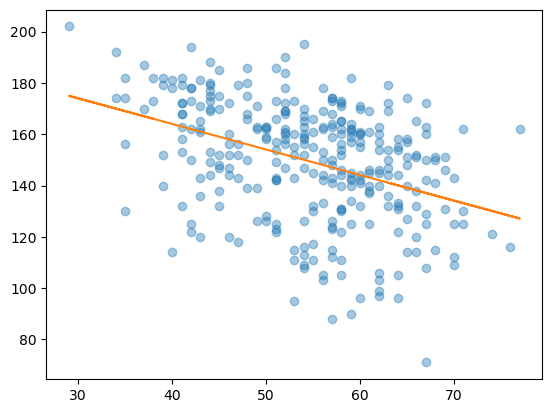

In [5]:
data_x = df_heart['Age']
data_y = df_heart['MaxHR']


reg = sk.linear_model.LinearRegression(fit_intercept=True)

model = reg.fit(data_x.values.reshape(-1,1), data_y)


print('R squared training',round(reg.score(data_x.values.reshape(-1,1),data_y),3))

print('beta0: ', reg.intercept_)
print('beta1: ', reg.coef_)

y_ = reg.predict(data_x.values.reshape(-1,1))
plt.plot(df_heart.Age, df_heart.MaxHR, 'o', alpha=0.4)
plt.plot(df_heart.Age, y_)
#plt.ylim(-0.1,1.1)
plt.show()

# Discuție:
    
 <b>Cum se interpreteaza coeficientii de regresie?</b>
 
 $y = \beta_0 + \beta_1 * x$

 
 Incercam sa vedem legatura intre puls maxim si varsta. Predictorul este vârsta, variabila de prognozat: pulsul maxim. 

Explicați cum se interpretează $\beta_1$.

## Explicația voastra aici (dublu click pentru editare):
   
$\beta_1$:

<b>Bonus</b> - cum se interpretează $\beta_0$:

 
 $y_1 = \beta_0 + \beta_1 * x_1$
  
 $y_2 = \beta_0 + \beta_1 * (x_1 + 1)$

 $\Delta(y) = y_2-y_1 = \beta_1$

# De ce nu putem clasifica cu regresie liniara?

## Exemplu - data legate de sanatate inimii

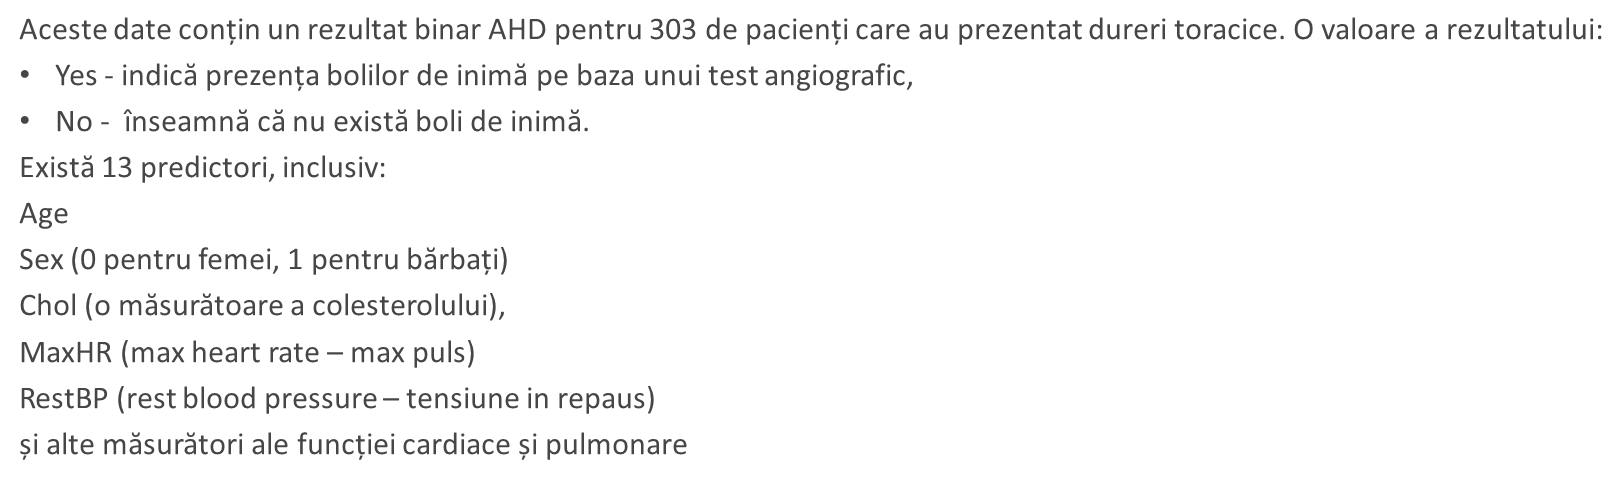

Transformăm AHD în  variabilă numerică pentru a încerca regresia:

In [6]:


df_heart['AHD'] = 1*(df_heart['AHD'] == "Yes")

df_heart.AHD.head(10)


0    0
1    1
2    1
3    0
4    0
5    0
6    1
7    0
8    1
9    1
Name: AHD, dtype: int32

Să observăm o diagramă de împrăștiere MaxHR și AHD:

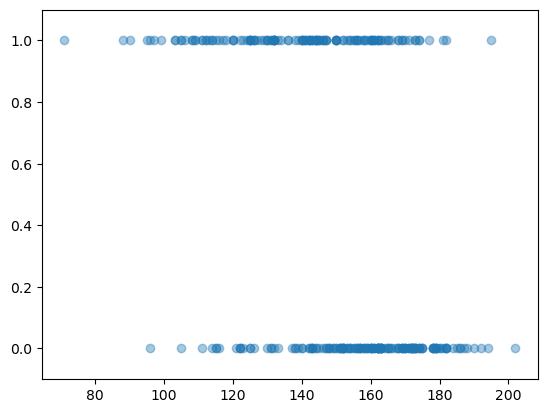

In [7]:
plt.plot(df_heart.MaxHR, df_heart.AHD, 'o', alpha=0.4)

plt.ylim(-0.1,1.1)
plt.show()


# Clasificare

   > Până în acest moment, metodele pe care le-am văzut s-au concentrat în jurul modelării și a prezicerii unei variabile de răspuns cantitativ (ex. Prețul unei mașini, pretul unei case etc.). Regresia liniară (și Ridge, LASSO, etc) funcționează bine în aceste situații.
   
   
   > Când variabila de răspuns este categorială, atunci problema nu mai este numită problemă de regresie, ci este în schimb etichetată ca o problemă de clasificare.
   
   
   > Scopul este clasificarea fiecărei observații într-o categorie (numită si clasă sau cluster) definită de $Y$, pe baza unui set de variabile predictor $X$.


   > Altel spus încercăm să modelăm  $P(AHD = 'Yes')$ sau, în graficul de mai sus, $P(𝑦 = 1)$

Adaugăm la graficul de mai sus dreapta de regresie:

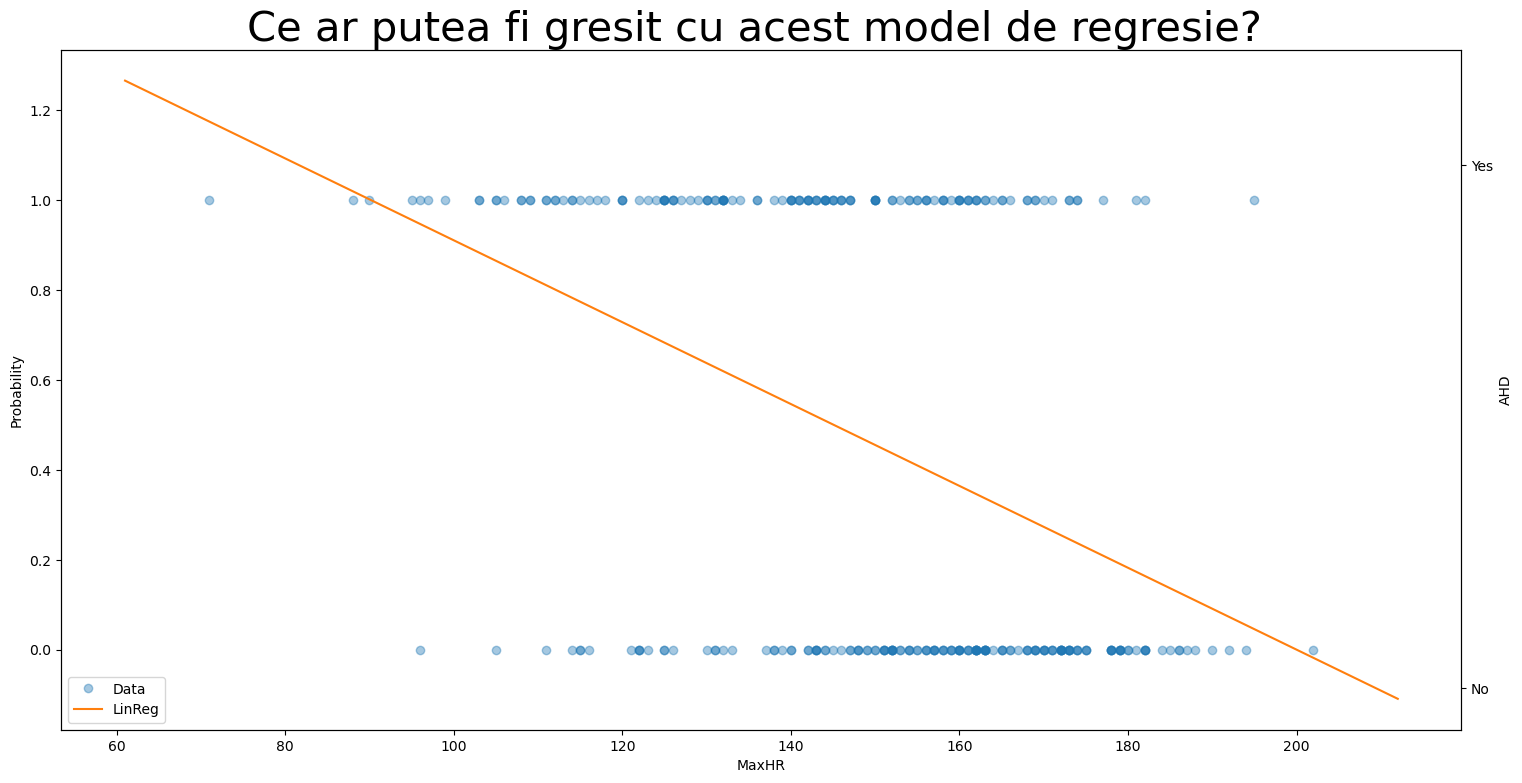

In [8]:
# plt.title('title',**csfont)
# plt.xlabel('xlabel', **hfont)
plt.show()
fig = plt.figure(figsize=(20,10))
fig.patch.set_alpha(0.0)

plt.gcf().subplots_adjust(bottom=0.20, left = 0.16, right=0.86)

host = fig.add_subplot(111)

par1 = host.twinx()

host.set_xlabel("MaxHR")
host.set_ylabel("Probability")


par1.set_ylabel("AHD")

color1 = plt.cm.viridis(0)

data_x = df_heart['MaxHR']
data_y = df_heart['AHD']

regr = sk.linear_model.LinearRegression(fit_intercept=True)

regr.fit(data_x.values.reshape(-1,1), data_y)


# Make predictions using the testing set
x=np.linspace(np.min(data_x)-10,np.max(data_x)+10)
y_ = regr.predict(x.reshape(-1,1))

host.plot(data_x, data_y, 'o' ,alpha=0.4, label='Data')

host.plot(x, y_, label='LinReg')
host.legend(loc=3)

labels = ['No', 'Yes']

# You can specify a rotation for the tick labels in degrees or with keywords.
par1.set_yticks( [0.061, 0.83])
par1.set_yticklabels(labels)
par1.set_title('Ce ar putea fi gresit cu acest model de regresie? ', fontsize=30)
plt.show()

#plt.savefig('fig/FittingLR.png', dpi=300, transparent=True)

Problema principală este că se pot obține valori fara sens pentru $y$. 

Deoarece aceasta este modelarea $P(𝑦 = 1)$, valorile pentru $\hat{y}$ sub 0 și peste 1 ar fi în contradicție cu măsura naturală pentru $y$. 

Regresia liniară poate duce la această problemă.


## De la regresie liniara la regresie logistica 

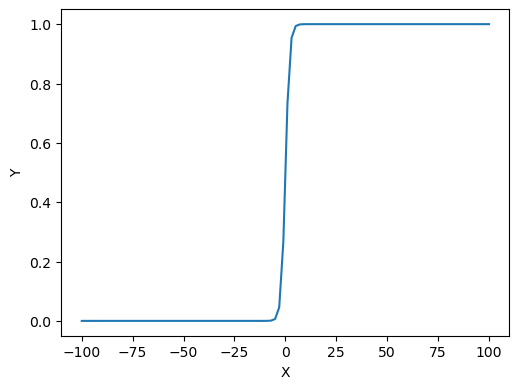

In [58]:
fig, ax1 = plt.subplots()
fig.patch.set_alpha(0.0)
#plt.xkcd(scale=0.1, length=0.0)
plt.gcf().subplots_adjust(bottom=0.20, left = 0.16, right=0.86)

x = np.linspace(-100, 100, 100)
y = x
yl = 1/(1+np.exp(-y))

ax1.plot(x,yl, label='Logistic(Y)')

ax1.set_xlabel('X')
ax1.set_ylabel('Y');

#ax1.legend()

#plt.savefig('fig/LinR.png', dpi=300, transparent=True)


Regresia ne dă o dreaptă. Pentru a modela probabilitățile, vom avea nevoie de o transformare a variabilei răspuns.

Regresia logistică abordează problema estimării unei probabilități, $P(y = 1)$, care să se afle în limitele $[0,1]$. Modelul de regresie logistică folosește o funcție, numită funcție logistică, pentru modelul $P(y = 1)$:
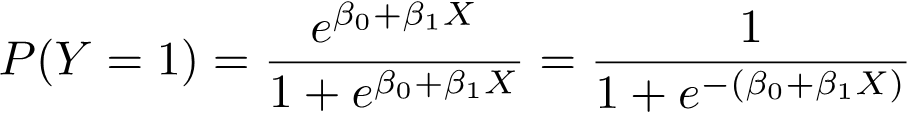

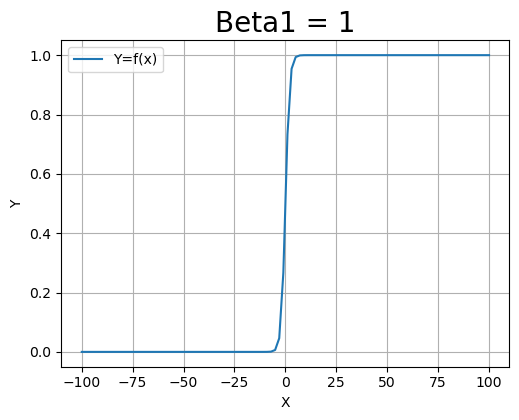

In [10]:
fig = plt.figure()
fig.patch.set_alpha(0.0)

plt.gcf().subplots_adjust(bottom=0.20, left = 0.16, right=0.86)


plt.plot(x,yl, label='Y=f(x)')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid()
plt.title('Beta1 = 1', fontsize = 20);
#plt.savefig('fig/LogR.png', dpi=300, transparent=True)


Drept urmare, modelul va prezice $P(y = 1)$ cu o curbă în formă de 𝑆, care este forma generală a funcției logistice.

$\beta_{0}$  deplasează curba spre dreapta sau stânga cu c=−$\frac{\beta_{0}}{\beta_{1}}$  .

$\beta_{1}$  controlează cât de abruptă este curba în formă de 𝑆. 

Distanța de la ½ la aproape 1 sau ½ la aproape 0 la ½ este $\frac{2}{\beta_{1}}$  

Notă: dacă $\beta_{1}$ este pozitiv, atunci $P(y = 1)$ trece de la 0 pentru valori mici ale lui $𝑋$ la 1 pentru valori mari de 𝑋 și dacă $\beta_{1}$ este negativ, atunci $P(y = 1)$ are asociere opusă.


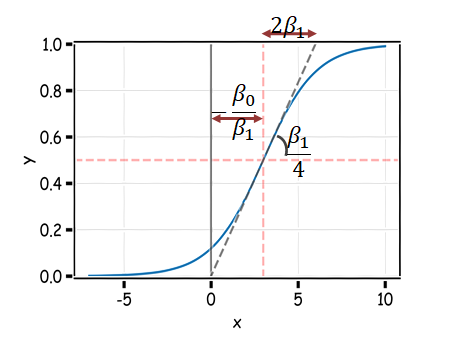

### Efectul coefficientilor in functia logistica

NOTĂ: animația de mai jos nu are nevoie de ffmpeg: se afișează ca player interactiv (`to_jshtml`) și se salvează ca GIF cu `PillowWriter`. Funcționează la fel în Colab și local.

In [ ]:
from IPython.display import HTML
import matplotlib as mpl
import matplotlib.animation


fig, ax = plt.subplots()
fig.patch.set_alpha(1.0)
#plt.xkcd(scale=0.1, length=0.0)
plt.gcf().subplots_adjust(bottom=0.20, left = 0.16, right=0.86)

line,  = ax.plot(x,yl, label=r'$Y=\frac{1}{1+e^{-(X+\beta_0) }}$')
plt.xlabel('X')
plt.ylabel('Y')
#plt.legend(loc=5)


def update(i):
    b1=2*i
    label = r'$\beta_1=$ {0}'.format(np.round(b1, decimals=2))
    #print(label)
    # Update the line and the axes (with a new xlabel). Return a tuple of
    # "artists" that have to be redrawn for this frame.
    line.set_ydata( 1/(1+np.exp(-b1*x)))
    ax.set_title(label)
    return line, ax


# FuncAnimation will call the 'update' function for each frame; here
# animating over 10 frames, with an interval of 200ms between frames.
anim = mpl.animation.FuncAnimation(fig, update, frames=np.arange(.4, -.4,-.02), interval=200, blit=False)

anim.save('LogBeta1.gif', writer=mpl.animation.PillowWriter(fps=20), dpi=120)

plt.close(fig)

HTML(anim.to_jshtml())


## Functia logit 

Cu un pic de algebra, modelul logistic poate fi rescris ca:


$ logit(x) = ln(\frac{P(Y=1|X=x)}{1-P(Y=1|X=x)}) = \beta_{0} + \beta_{1} \times x$

Să reținem că $\frac{P(Y=1|X=x)}{1-P(Y=1|X=x)}$, se numește <b>șansă (odds)</b>.

Regresia logistică se spune că modelează log odds cu o funcție liniară a predictorilor sau a caracteristicilor, $X$. 

Aceasta ne oferă interpretarea naturală a estimărilor similare cu regresia liniară: 
- o modificare a unei unități în $X$ este asociată cu o modificare  $\beta_{1}$ in log-odds pentru clasa $𝑌=1$; 
- altfel spus, <b>o schimbare de o unitate în $X$ este asociată cu o modificare de $e^{\beta_{1}}$ în șansă (definită mai sus) ca $𝑌=1$.</b> 


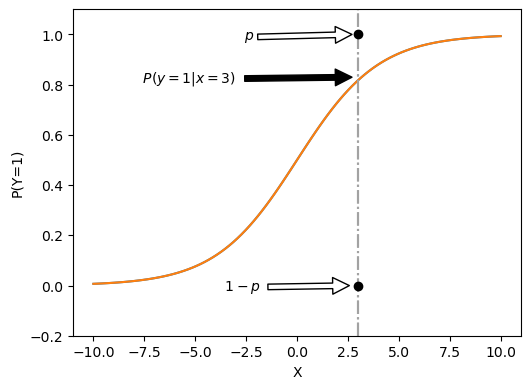

In [61]:
fig = plt.figure()
fig.patch.set_alpha(0.0)
#plt.xkcd(scale=0.1, length=0.0)


plt.gcf().subplots_adjust(bottom=0.20, left = 0.16, right=0.86)


x = np.linspace(-10, 10, 100)
y = x
yl = 1/(1+np.exp(-0.5*y))

#plt.plot(x,yl, label=r'$P(Y=1)=\frac{1}{1+e^{-X\beta}}$')
plt.plot(x,yl)
plt.xlabel('X')
plt.ylabel('P(Y=1)')
#plt.legend()
plt.ylim((-0.2, 1.1))
#plt.savefig('fig/Likelihood1.png', dpi=300, transparent=True)

### FRAME 2 

plt.axvline(x=3, color='#A2A2A2', ls='-.')
#plt.savefig('fig/Likelihood2.png', dpi=300, transparent=True)

### FRAME 3
plt.annotate(r'  $P(y=1|x=3)$', xy=(3, .83),\
             xytext=(-8, .81),
            arrowprops=dict(facecolor='black', shrink=0.05),
            )
plt.savefig('Likelihood3.png', dpi=300, transparent=True)


#plt.clf()
plt.ylim((-0.2, 1.1))
plt.plot(x,yl)
plt.xlabel('X')
plt.ylabel('P(Y=1)')
plt.axvline(x=3, color='#A2A2A2', ls='-.')
coinf = np.random.binomial(1, 0.7, size=1)
plt.plot( [3], [0], 'ko')
plt.plot( [3], [1], 'ko')

plt.annotate(r'  $p$', xy=(2.7, 1),\
             xytext=(-3, 0.98),
            arrowprops=dict(facecolor='white', shrink=0.0),
            )
plt.annotate(r'  $1-p$', xy=(2.8, .00),\
             xytext=(-4, -.02),
            arrowprops=dict(facecolor='white', shrink=0.05),
            )
plt.savefig('Likelihood5.png', dpi=300, transparent=True);

#plt.show()



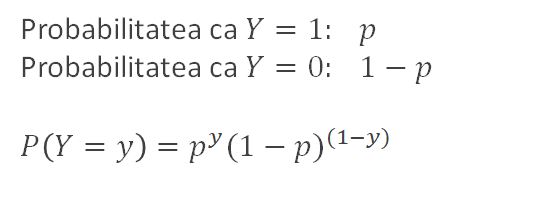

unde:
$p=p(x) = P(𝑌=1|X=x)$ și, prin urmare, $p$ depinde de eșantionul $X$.


# Estimarea parametrilor beta

Nu mai exista formă inchisă, se minimizează cu tehnici de aproximare care sunt dincolo de scopul cursului.

Funcția care se minimizează:

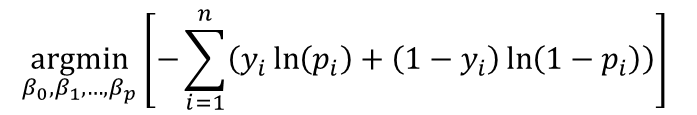

unde:
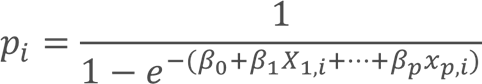

## Revenim la exemplu

Vrem să estimăm probabilitatea $AHD = 1$ folosind predictorul MaxHR.

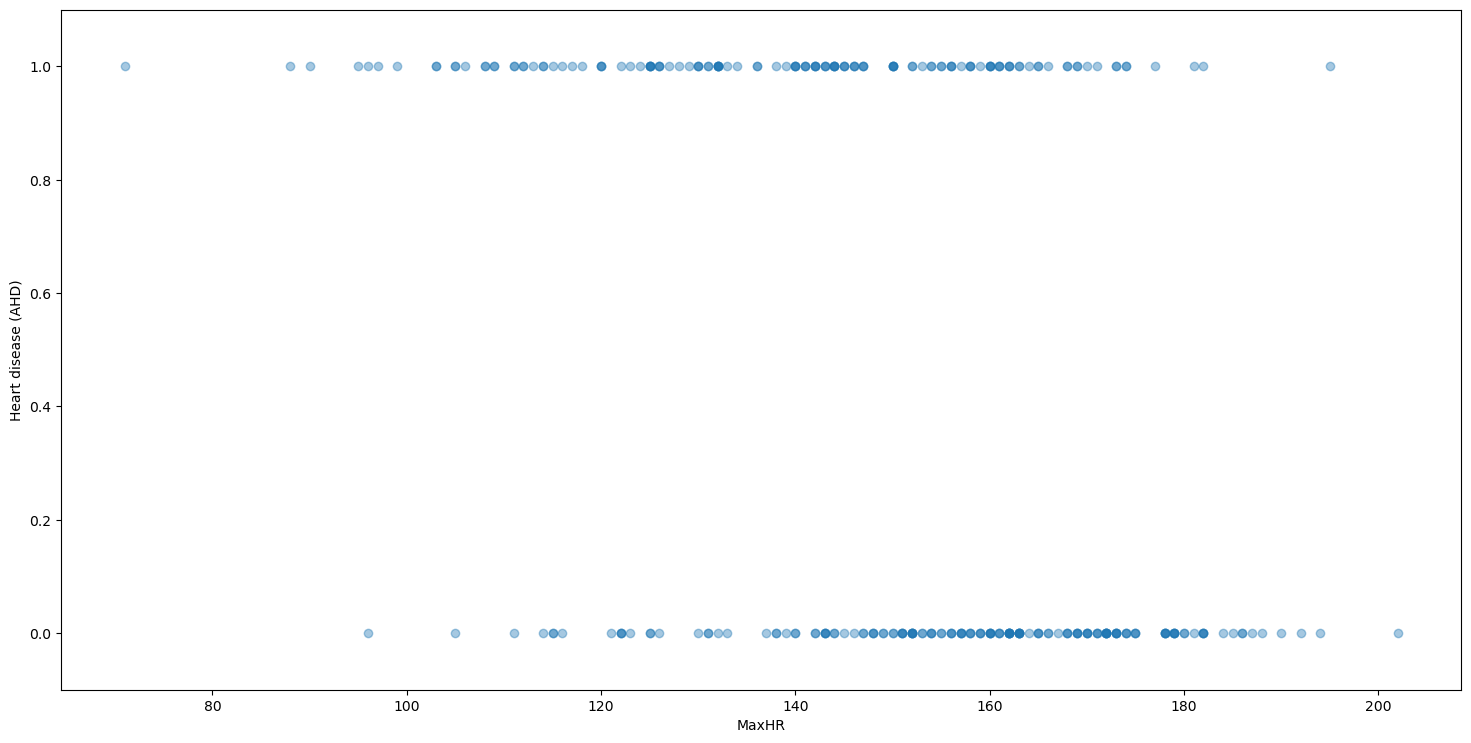

In [15]:
from sklearn import linear_model

fig = plt.figure(figsize=(20,10))
fig.patch.set_alpha(0.0)
#plt.xkcd(scale=0.1, length=0.0)
plt.gcf().subplots_adjust(bottom=0.20, left = 0.16, right=0.86)

plt.ylim((-0.1, 1.1))


plt.xlabel("MaxHR")
plt.ylabel("Heart disease (AHD)")


data_x = df_heart['MaxHR']
data_y = df_heart['AHD']

plt.plot(data_x, data_y, 'o' ,alpha=0.4, label='Data')
plt.show()



Așa cum ne-am obișnuit, avem de efectuat 2 pași:
    
    - fit (antrenament, sau estimare parametrii pe date de antrenament)
    - predicție
    
Despre parametrul C de mai jos vom vorbi imediat.

Există diferite variante de modelare a regresiei logistice în Python.

Cea mai directă este sklearn via linear_model.LogisticRegression.

In [16]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(C=100000, fit_intercept=True,solver='lbfgs')
logreg.fit(data_x.values.reshape(-1,1), data_y);

print('Estimated beta1: \n', logreg.coef_)
print('Estimated beta0: \n', logreg.intercept_)

Estimated beta1: 
 [[-0.04341112]]
Estimated beta0: 
 [6.3249492]


In [17]:
data_x.values.reshape(-1,1),data_y

(array([[150],
        [108],
        [129],
        [187],
        [172],
        [178],
        [160],
        [163],
        [147],
        [155],
        [148],
        [153],
        [142],
        [173],
        [162],
        [174],
        [168],
        [160],
        [139],
        [171],
        [144],
        [162],
        [160],
        [173],
        [132],
        [158],
        [172],
        [114],
        [171],
        [114],
        [151],
        [160],
        [158],
        [161],
        [179],
        [178],
        [120],
        [112],
        [132],
        [137],
        [114],
        [178],
        [162],
        [157],
        [169],
        [165],
        [123],
        [128],
        [157],
        [152],
        [168],
        [140],
        [153],
        [188],
        [144],
        [109],
        [163],
        [158],
        [152],
        [125],
        [142],
        [160],
        [131],
        [170],
        [113],
        [142],
        [1

Să inspectăm modelul logistic rezultat

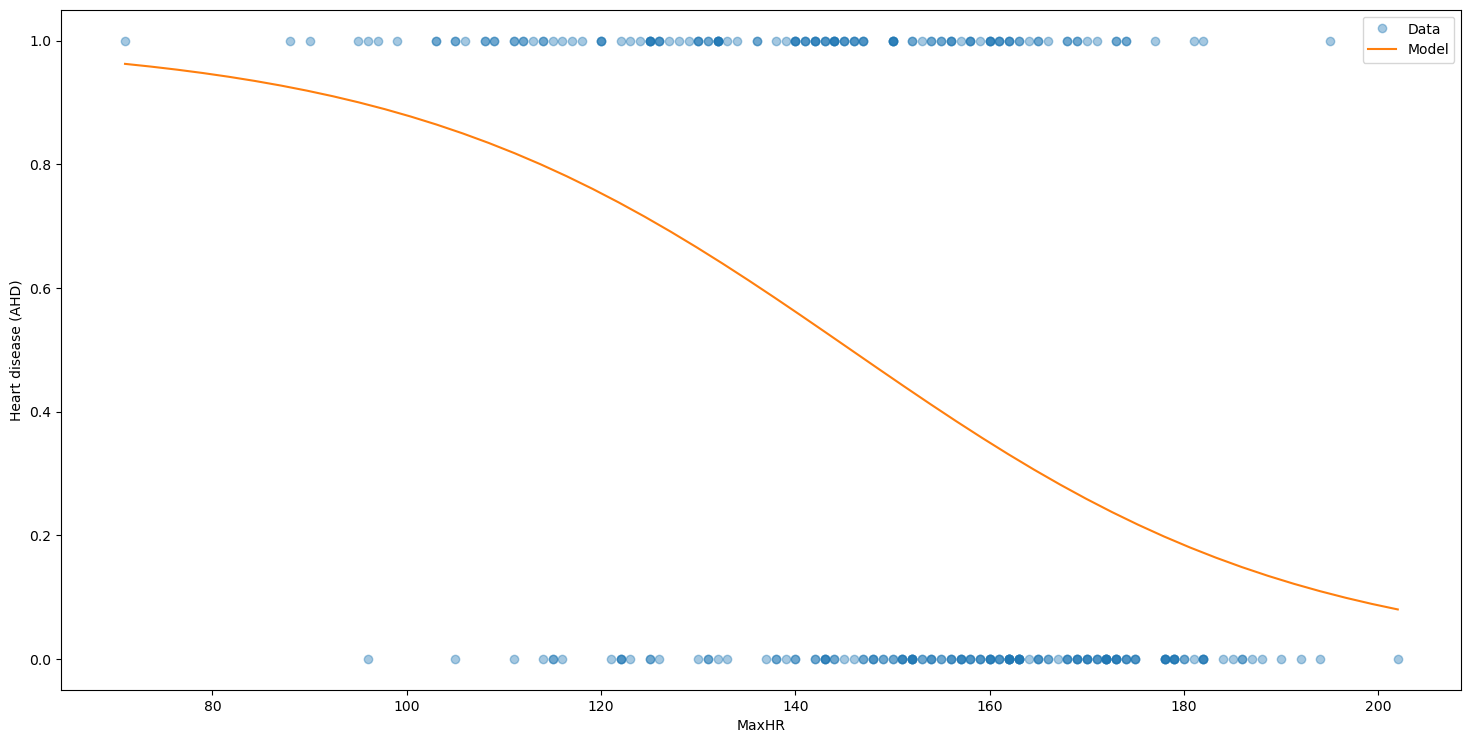

In [18]:

fig = plt.figure(figsize=(20,10))
fig.patch.set_alpha(0.0)
#plt.xkcd(scale=0.1, length=0.0)
plt.gcf().subplots_adjust(bottom=0.20, left = 0.16, right=0.86)


x=np.linspace(np.min(data_x),np.max(data_x))
yhat = logreg.predict_proba(x.reshape(-1,1))[:,1]
plt.plot(data_x, data_y, 'o' ,alpha=0.4, label='Data')
plt.plot(x,yhat, label='Model')
plt.legend()

plt.xlabel("MaxHR")
plt.ylabel("Heart disease (AHD)")

plt.savefig('FittingLogR2.png', dpi=300, transparent=True)

In [19]:
yhat = logreg.predict_proba(x.reshape(-1,1))
yhat

array([[0.03758793, 0.96241207],
       [0.04201919, 0.95798081],
       [0.04694736, 0.95305264],
       [0.05242191, 0.94757809],
       [0.05849565, 0.94150435],
       [0.06522468, 0.93477532],
       [0.07266804, 0.92733196],
       [0.08088732, 0.91911268],
       [0.08994609, 0.91005391],
       [0.0999091 , 0.9000909 ],
       [0.11084126, 0.88915874],
       [0.12280642, 0.87719358],
       [0.13586584, 0.86413416],
       [0.15007642, 0.84992358],
       [0.16548868, 0.83451132],
       [0.18214452, 0.81785548],
       [0.2000748 , 0.7999252 ],
       [0.21929686, 0.78070314],
       [0.23981203, 0.76018797],
       [0.26160329, 0.73839671],
       [0.28463327, 0.71536673],
       [0.30884269, 0.69115731],
       [0.3341494 , 0.6658506 ],
       [0.36044832, 0.63955168],
       [0.38761217, 0.61238783],
       [0.41549319, 0.58450681],
       [0.44392589, 0.55607411],
       [0.47273068, 0.52726932],
       [0.50171816, 0.49828184],
       [0.5306941 , 0.4693059 ],
       [0.

In [20]:
print('Estimated beta1: \n', logreg.coef_)
print('Estimated beta0: \n', logreg.intercept_)
print(f'Prob( Y = 1 | X = x) = 1/(1+ np.exp(-({logreg.intercept_[0]:0.2f} + {logreg.coef_[0][0]:0.2f}*x ) ))')

Estimated beta1: 
 [[-0.04341112]]
Estimated beta0: 
 [6.3249492]
Prob( Y = 1 | X = x) = 1/(1+ np.exp(-(6.32 + -0.04*x ) ))


## Exercițiul 1 - laborator

Răspundeți la câteva întrebări:
1. Scrieți modelul de regresie logistică pentru funcția de mai sus.
2. Interpretati $\widehat{\beta}_{1}$.
3. Estimați probabilitatea de boală cardiacă pentru cineva cu MaxHR≈200.
4. Dacă ar fi să folosim acest model pur pentru clasificare, cum am face? 

In [21]:
logreg.predict_proba([[200]])[0][1]

0.08648927334594537

In [22]:
#cum facem sa facem mai multe prognoze deodata? cum organizam inputul? sa zicem MaxHR sa fie 107 si 213.
valori = [[107], [219]]
print(logreg.predict_proba(valori))
[p for p in logreg.predict(valori)]

[[0.15710084 0.84289916]
 [0.96015455 0.03984545]]


[1, 0]

In [23]:
intercept = logreg.predict_proba([[0]])


In [24]:
b0 = logreg.intercept_
b1 = logreg.coef_

print(1/(1+np.exp(-b0-b1*49)))

[[0.98519397]]


## Predictori categoriali

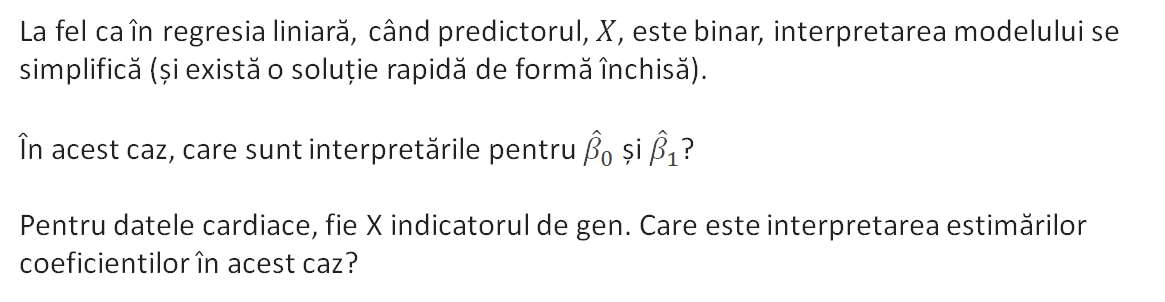

### INDICAȚIE:
$X$ nu ia decât două valori, 0 sau 1. Deci $P(Y=1|X=x)$ nu are decât două posibilități: cea pentru $X = 0$ și cea pentru $X = 1$.

   Sex  AHD  size
0    0    0    72
1    0    1    25
2    1    0    92
3    1    1   114


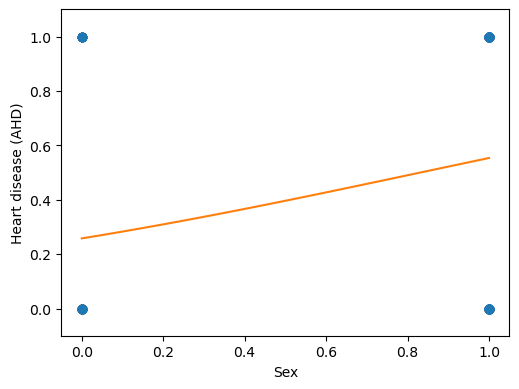

Estimated beta0:  -1.0570878978112246
Estimated beta1:  1.2714763971510226


In [25]:
fig = plt.figure()
fig.patch.set_alpha(0.0)
#plt.xkcd(scale=0.1, length=0.0)
plt.gcf().subplots_adjust(bottom=0.20, left = 0.16, right=0.86)

plt.ylim((-0.1, 1.1))

plt.xlabel("Sex")
plt.ylabel("Heart disease (AHD)")


data_x = df_heart['Sex']
data_y = df_heart['AHD']
logreg.fit(data_x.values.reshape(-1,1), data_y);

x=np.linspace(np.min(data_x),np.max(data_x))
yhat = logreg.predict_proba(x.reshape(-1,1))[:,1]
print(df_heart.groupby(['Sex','AHD'], as_index=False).size())
plt.plot(data_x, data_y, 'o' ,alpha=0.4, label='Data')
plt.plot(x,yhat, label='Model')
plt.show()
print(f'Estimated beta0:  {logreg.intercept_[0]}')
print(f'Estimated beta1:  {logreg.coef_[0][0]}')



In [26]:
25/(25+72)

0.25773195876288657

In [27]:
114/(114+92)

0.5533980582524272

In [28]:

print(f'P(y = 1|x = 0) =  {1/(1+np.exp(-logreg.intercept_))[0]}, P(y = 1|x = 1) =  : {1/(1+np.exp(-logreg.intercept_-logreg.coef_))[0][0]}')

P(y = 1|x = 0) =  0.25786635439860456, P(y = 1|x = 1) =  : 0.5533927761841095


In [29]:
data_x = df_heart['Sex']
data_y = df_heart['AHD']

idx0 = np.where(data_x.values==0)
idx1 = np.where(data_x.values==1)

print(f"procent femei cu HD: {100*data_y.values[idx0].sum()/idx0[0].shape[0]:0.2f}%",)
print(f"procent barbati cu HD {100*data_y.values[idx1].sum()/idx1[0].shape[0]:0.2f}%")
print(f"procent subiecti cu HD {100*(data_y.values[idx0].sum() + data_y.values[idx1].sum())/df_heart.shape[0]:0.2f}%")

pd.crosstab(df_heart['Sex'],df_heart['AHD'])


procent femei cu HD: 25.77%
procent barbati cu HD 55.34%
procent subiecti cu HD 45.87%


AHD,0,1
Sex,,
0,72,25
1,92,114


# Sunt posibile două extensii: 
- mărim numărul de predictori - Regresie Logistică Multiplă
- mărim numarul de clase - Regresie Logistica Multinomială

Cea mai generală formă este cea a Regresiei Logistice Multiple Multinomiale (sau cu clase/categorii multiple)

## Regresie Logistică Multiplă

In [30]:
data_x = df_heart[['MaxHR','Sex']]
data_y = df_heart['AHD']

logreg.fit(data_x, data_y)


print('Estimated beta1, beta2: \n', logreg.coef_)
print('Estimated beta0: \n', logreg.intercept_)

Estimated beta1, beta2: 
 [[-0.04508908  1.40621576]]
Estimated beta0: 
 [5.60186105]


In [31]:
# introducem un termen de interactiune (ceea ce nu am incercat la regresie liniara...)

df_heart['Interaction'] = df_heart.MaxHR * df_heart.Sex 

data_x = df_heart[['MaxHR','Sex', 'Interaction']]
data_y = df_heart['AHD']

logreg = LogisticRegression(C=100000, fit_intercept=True, solver='lbfgs')
logreg.fit(data_x, data_y)


print('Estimated beta1, beta2, beta3: \n', logreg.coef_)
print('Estimated beta0: \n', logreg.intercept_)

Estimated beta1, beta2, beta3: 
 [[-0.02660855  5.41777432 -0.02708773]]
Estimated beta0: 
 [2.90445935]


In [32]:
df_heart.AHD.value_counts()

AHD
0    164
1    139
Name: count, dtype: int64

              precision    recall  f1-score   support

           0       0.70      0.80      0.75       164
           1       0.72      0.60      0.65       139

    accuracy                           0.71       303
   macro avg       0.71      0.70      0.70       303
weighted avg       0.71      0.71      0.71       303



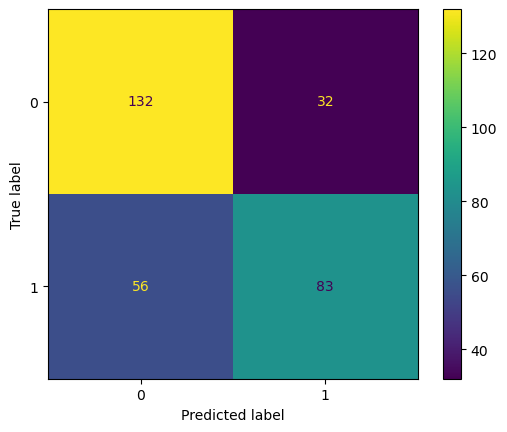

In [33]:
from sklearn.metrics import classification_report,confusion_matrix

y_train_hat = logreg.predict(data_x)
print(classification_report(data_y, y_train_hat))
disp= sk.metrics.ConfusionMatrixDisplay(confusion_matrix(y_true = data_y, y_pred = y_train_hat))
disp.plot()

# Exercițiul 2 - laborator:
Construiți un model logistic cu toți predictorii numerici, 2 clase.

# Clasificare cu Regresia Logistica
- antrenament (estimare parametrii)
- predicții

Cum putem folosi un model de regresie logistică pentru a efectua clasificarea?
Adică, cum putem prezice când $𝑌 = 1$ vs. $𝑌 = 0$?

Am menționat anterior, putem clasifica toate observațiile pentru care $\hat{P}(𝑌 = 1) ≥0.5$ să fie în grupul asociat cu $𝑌 = 1$ și apoi să asociem toate observațiile pentru care $\hat{P}(𝑌 = 0) <0.5$ cu grupul cu $𝑌 = 0$.

Utilizarea unei asemenea abordări definește <b>clasificatorul standard Bayes</b>.
Clasificatorul Bayes adoptă abordarea care atribuie fiecărei observații clasa cea mai probabilă, având în vedere valorile sale de predictor.

## Evaluarea unui model de clasificare:


## Matrici de confuzie 

In general clasa prevalenta in setul de antrenament va fi etichetata cu 1 si este adesea numita `clasa pozitiva` iar cealalta cu 0 - `clasa negativa`. Algoritmul va genera rezulta asociind o eticheta prognozata 1 sau 0 unei inregistrari din setul de antrenament (in pasul de `fit`) si din setul de test (in pasul de `predict`).

Există 2 tipuri majore de erori în problemele de clasificare bazate pe un rezultat binar. Sunt:

 > `Fals positive`(FP): prezicerea incorectă $\hat{𝑌}= 1$ atunci când este cu adevărat în $𝑌 = 0$.
 
 > `Fals negative`(FN): prezicerea incorectă 𝑌 ̂ = 0 atunci când este cu adevărat în 𝑌 = 1.

Succesul pe de alta parte se masoara in:
 
 > `True positive`(TP): prezicerea corectă $\hat{𝑌}= 1$ atunci când este cu adevărat în 𝑌 = 1.
 
 > `True negative`(TN): prezicerea corectă $\hat{𝑌}= 0$ atunci când este cu adevărat în 𝑌 = 0.

Pentru cele patru notiuni se folosesc atat valorile efective, cat si o sumedenie de metrici derivate (sursa https://en.wikipedia.org/wiki/Confusion_matrix):
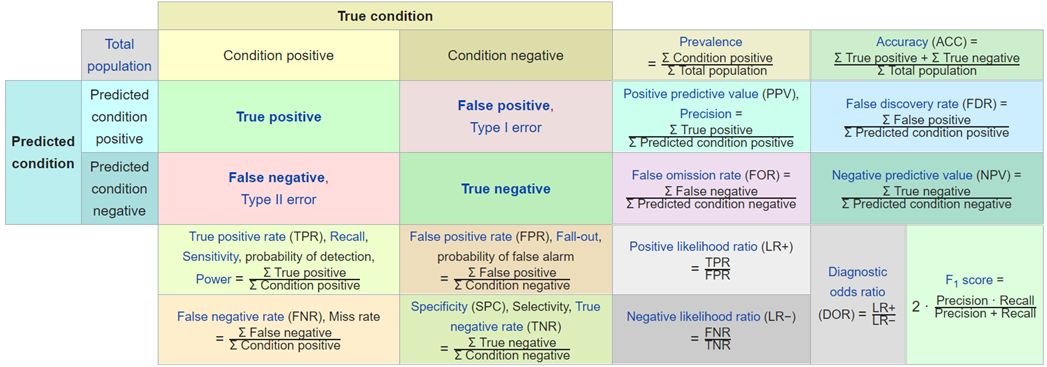

In particular sunt folosite frecvent in algoritmii de prognoza metricile

> Recall/True positive rate/Sensitivity: `TPR/Recall`$ = \frac{TP}{TP+FN}$ 

> Precision/Positive Predicted Value: `Precision`$ = \frac{TP}{TP+FP}$

> `F-Score`: F $_\beta = (1+\beta^2)\cdot \frac{Precision\cdot Recall}{\beta^2\cdot Precision+Recall}$

In particular $\beta =1$ si $F_1$ este media armonica intre Precision si Recall.

Rezultatele unui algoritm de clasificare sunt adesea rezumate în două moduri:

1. o matrice de confuzie, numită uneori tabel de contingență
2. curba ROC si aria de sub ea

Metrici foarte des întâlnite în clasicare:
- Precision, Recall, F1

In [34]:
import sklearn as sk
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
import sklearn.metrics as met

In [35]:
logreg.fit(df_heart[['Sex','MaxHR','Interaction']], df_heart['AHD'])

# Coeficienții
print('Estimare beta1: \n', logreg.coef_)
print('Estimare beta0: \n', logreg.intercept_)

Estimare beta1: 
 [[ 5.41777432 -0.02660855 -0.02708773]]
Estimare beta0: 
 [2.90445935]


In [36]:
df_heart.groupby('AHD').count()

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,Interaction
AHD,,,,,,,,,,,,,,
0,164,164,164,164,164,164,164,164,164,164,164,161,163,164
1,139,139,139,139,139,139,139,139,139,139,139,138,138,139


In [37]:
yhat>0.5

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

In [38]:
#calculating confusion matrices
import numpy as np
yhat_full = logreg.predict_proba(df_heart[['Sex','MaxHR','Interaction']])


yhat= yhat_full[:,1]
print('Media prognozelor de probabilitate este ', np.mean(yhat))

print('Matricea de confuzie cu separarea claselor la 0.5: \n',met.confusion_matrix(y_true = df_heart['AHD'], y_pred = yhat>0.5))
print('Matricea de confuzie cu separarea cl aselor la ',np.mean(yhat),'\n',met.confusion_matrix(df_heart['AHD'], yhat>np.mean(yhat)))
print('Matricea de confuzie cu separarea claselor la 0.72: \n',met.confusion_matrix(df_heart['AHD'], yhat>0.72))
print('Matricea de confuzie cu separarea claselor la 0.25: \n',met.confusion_matrix(df_heart['AHD'], yhat>0.25))

Media prognozelor de probabilitate este  0.45874585272988005
Matricea de confuzie cu separarea claselor la 0.5: 
 [[132  32]
 [ 56  83]]
Matricea de confuzie cu separarea cl aselor la  0.45874585272988005 
 [[122  42]
 [ 47  92]]
Matricea de confuzie cu separarea claselor la 0.72: 
 [[156   8]
 [ 89  50]]
Matricea de confuzie cu separarea claselor la 0.25: 
 [[ 74  90]
 [ 14 125]]


In [39]:
df_heart['AHD'].value_counts()

AHD
0    164
1    139
Name: count, dtype: int64

In [40]:
met.confusion_matrix(y_true = df_heart['AHD'], y_pred = yhat>0.5)

array([[132,  32],
       [ 56,  83]], dtype=int64)

In [41]:
met.confusion_matrix(y_pred = yhat>0.5, y_true = df_heart['AHD'] )

array([[132,  32],
       [ 56,  83]], dtype=int64)

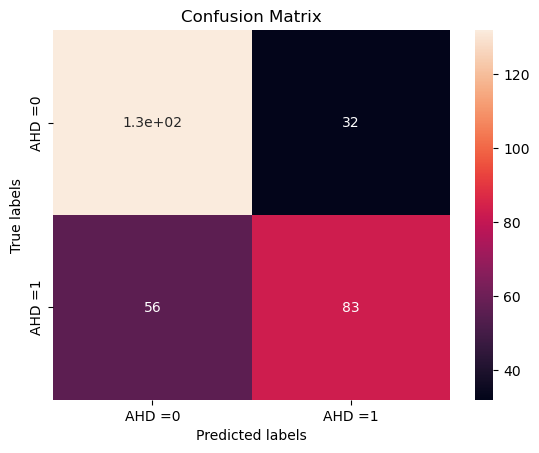

In [42]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib

ax= plt.subplot()
labels = ['Abnormal','Normal']
cm = met.confusion_matrix(df_heart['AHD'], yhat>0.5) #confusion_matrix(y_test_string, y_pred_string, labels)
sns.heatmap(cm, annot=True, ax = ax); #annot=True to annotate cells

# labels, title and ticks
ax.set_xlabel('Predicted labels');ax.set_ylabel('True labels'); 
ax.set_title('Confusion Matrix'); 
ax.xaxis.set_ticklabels(['AHD =0', 'AHD =1']); ax.yaxis.set_ticklabels(['AHD =0', 'AHD =1']);
plt.show()

# Exercitiul 3 - laborator

Calculați Recall, Precision și F1 pentru toate modelele de regresie logistică simplă din datele de mai sus,
cu pragul fixat la 0.5 pentru discriminare între clase.

Asta inseamna:
- împărțiți datele în date de antrenament și de test
- pentru fiecare din predictori antrenați un model de regresie logistică
- preziceti pe datele de test și produceți matricea de confuzie

Calculați Recall, Precision și F1.

În funcție de F1 faceți topul celor mai buni predictori.


In [43]:
df_heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          303 non-null    int64  
 1   Sex          303 non-null    int64  
 2   ChestPain    303 non-null    object 
 3   RestBP       303 non-null    int64  
 4   Chol         303 non-null    int64  
 5   Fbs          303 non-null    int64  
 6   RestECG      303 non-null    int64  
 7   MaxHR        303 non-null    int64  
 8   ExAng        303 non-null    int64  
 9   Oldpeak      303 non-null    float64
 10  Slope        303 non-null    int64  
 11  Ca           299 non-null    float64
 12  Thal         301 non-null    object 
 13  AHD          303 non-null    int32  
 14  Interaction  303 non-null    int64  
dtypes: float64(2), int32(1), int64(10), object(2)
memory usage: 34.5+ KB


In [44]:
df_heart2 = pd.get_dummies(df_heart, columns = ['Thal','ChestPain'], prefix = ['Thal','Chestpain'], drop_first=[True,True])
#df_heart2 = pd.get_dummies(df_heart2.ChestPain, prefix = 'Chestpain',drop_first=True)
df_heart2


,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,AHD,Interaction,Thal_normal,Thal_reversable,Chestpain_nonanginal,Chestpain_nontypical,Chestpain_typical
0,63,1,145,233,1,2,150,0,2.3,3,0.0,0,150,False,False,False,False,True
1,67,1,160,286,0,2,108,1,1.5,2,3.0,1,108,True,False,False,False,False
2,67,1,120,229,0,2,129,1,2.6,2,2.0,1,129,False,True,False,False,False
3,37,1,130,250,0,0,187,0,3.5,3,0.0,0,187,True,False,True,False,False
4,41,0,130,204,0,2,172,0,1.4,1,0.0,0,0,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,110,264,0,0,132,0,1.2,2,0.0,1,132,False,True,False,False,True
299,68,1,144,193,1,0,141,0,3.4,2,2.0,1,141,False,True,False,False,False
300,57,1,130,131,0,0,115,1,1.2,2,1.0,1,115,False,True,False,False,False
301,57,0,130,236,0,2,174,0,0.0,2,1.0,1,0,True,False,False,True,False


In [45]:
from sklearn.model_selection import train_test_split
df_heart2 = pd.get_dummies(df_heart, columns = ['Thal','ChestPain'], prefix = ['Thal','Chestpain'], drop_first=[True,True])
df_heart2.dropna(inplace=True   )
X_train, X_test, y_train, y_test = train_test_split(df_heart2,
df_heart2["AHD"],
test_size=0.3,
random_state=42)

for predictors in [['MaxHR'],['Sex'],['MaxHR','Sex'],X_train.columns.tolist()]:
    X_train, X_test, y_train, y_test = train_test_split(
        df_heart2[predictors],
        df_heart2["AHD"],
        test_size=0.3,
        random_state=42
    )   

    logreg = LogisticRegression(C=100000, fit_intercept=True, solver='lbfgs', max_iter=1000)
    logreg.fit(X_train, y_train)
    yhat = logreg.predict(X_test)
    print(f'Using predictors: {predictors}')
    print('confusion matrix : ', met.confusion_matrix(y_test, yhat))
    print('classification report : \n', met.classification_report(y_test, yhat))

Using predictors: ['MaxHR']
confusion matrix :  [[41 12]
 [14 23]]
classification report : 
               precision    recall  f1-score   support

           0       0.75      0.77      0.76        53
           1       0.66      0.62      0.64        37

    accuracy                           0.71        90
   macro avg       0.70      0.70      0.70        90
weighted avg       0.71      0.71      0.71        90

Using predictors: ['Sex']
confusion matrix :  [[22 31]
 [ 7 30]]
classification report : 
               precision    recall  f1-score   support

           0       0.76      0.42      0.54        53
           1       0.49      0.81      0.61        37

    accuracy                           0.58        90
   macro avg       0.63      0.61      0.57        90
weighted avg       0.65      0.58      0.57        90

Using predictors: ['MaxHR', 'Sex']
confusion matrix :  [[41 12]
 [13 24]]
classification report : 
               precision    recall  f1-score   support

       

# Curba ROC (Receiver Operator Statistic)

ROC est o comparație a două caracteristici de operare (TPR și FPR) pe măsură ce criteriul se schimbă.

In cazul regresiei logistice se livrează la predicție o valoare intre 0  si 1, care este interpretată ca și probabilitatea ca $Y = 1$ dacă se specifică valoarea predictorilor $X$.

Pentru a genera o matrice de confuzie și a ne hotărâ asupra asocierii acestei predicții cu una dintre clasele 0,1 trebuie să precizăm un prag. 

Deasupra pragului valorile vor fi asociate cu clasa pozitivă, sub prag cu cea negativă.

In [46]:
predictors = ['MaxHR','Sex']
X_train, X_test, y_train, y_test = train_test_split(
        df_heart2[predictors],
        df_heart2["AHD"],
        test_size=0.3,
        random_state=42
    )   

logreg = LogisticRegression(C=100000, fit_intercept=True, solver='lbfgs', max_iter=1000)
logreg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,100000
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


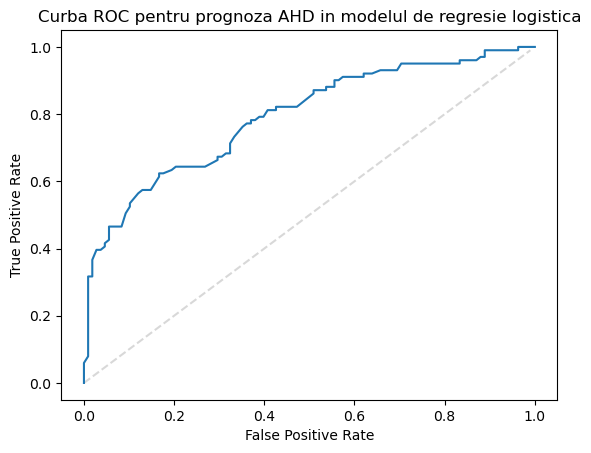

In [47]:
#ROC curve on the train set
from sklearn import metrics as met
fpr, tpr, thresholds = met.roc_curve(y_train, logreg.predict_proba(X_train)[:,1])

x=np.arange(0,100)/100
plt.plot(x,x,'--',color="gray",alpha=0.3)
plt.plot(fpr,tpr)
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.title("Curba ROC pentru prognoza AHD in modelul de regresie logistica")
plt.show()

In [48]:
import plotly.graph_objects as go
import numpy as np
from plotly.subplots import make_subplots
from plotly.offline import plot

fig = go.Figure() #make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(go.Scatter(x= np.linspace(0,1,1000), 
                         y= np.linspace(0,1,1000),
                         name = "50/50 chance",
                         line=dict(color='gray', width=2, dash='dot')) )

fig.add_trace(go.Scatter(x=fpr, 
                      y=tpr,
                      name = "ROC",
                      line = dict(color ='blue', width=2),
                      hovertext=thresholds) )

fig.update_layout(
                    title="Curba ROC pentru prognoza AHD in modelul de regresie logistica",
                    xaxis_title="FPR",

                    font=dict(
                        size=10,
                        color="#7f7f7f"
                    )
                )

# Set y-axes titles
fig.update_yaxes(title_text="TPR")#, secondary_y=False)

fig.show()

# Exercitiul 4 - laborator

Pentru cazul celui mai bun predictor de mai sus, considerati modelul de regresie logistica si desenati curba ROC. 

## Aria Under the Curve (AUC)

Performanța generală a unui clasificator, calculată peste toate pragurile posibile, este dată de zona de sub curba ROC („AUC” - area under the curve).

O curbă ROC ideală va îmbrățișa colțul din stânga sus, deci cu cât AUC este mai mare cu atât clasificatorul este mai bun.

Care este cel mai rău caz pentru AUC? Care este cel mai bun caz? Ce este AUC dacă aruncăm independent o monedă pentru a efectua clasificarea ("dăm cu banul")?

Acest AUC poate fi folosit pentru a compara diverse abordări ale clasificării care genereaza o probabilitate de apartenenta la o clasa: regresie logistică, k-NN, etc.

# Parametrii si Importanta Predictorilor - Exemplu Regularizare - parametrul C

La fel ca la Lasso regression, se poate exploata regularizarea pentru a determina un model optim.

In cazul acesta C este inversul parametrului considerat in Lasso regression.

Pentru determinarea celui mai bun C se considera un sir de valori si se observa efectul asupra modelului.

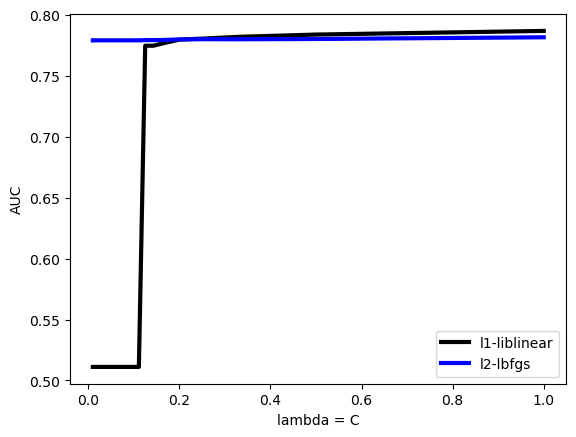

[array([-0.02658485,  3.8163109 , -0.01675304]),
 array([-0.02656405,  2.50745922, -0.00828374]),
 array([-2.65651556e-02,  1.38892161e+00, -1.02594903e-03]),
 array([-0.02547493,  0.61246024,  0.00396928]),
 array([-0.02399784,  0.        ,  0.00792151]),
 array([-0.01963004,  0.        ,  0.00783512]),
 array([-0.01542965,  0.        ,  0.00777303]),
 array([-0.01133776,  0.        ,  0.00773287]),
 array([-0.00733897,  0.        ,  0.0077131 ]),
 array([-0.00733409,  0.        ,  0.00770744]),
 array([-0.00732932,  0.        ,  0.00770174]),
 array([-0.00732431,  0.        ,  0.00769583]),
 array([-0.00731952,  0.        ,  0.0076902 ]),
 array([-0.00731464,  0.        ,  0.00768445]),
 array([-0.00730991,  0.        ,  0.00767891]),
 array([-0.00730509,  0.        ,  0.00767323]),
 array([-0.00730026,  0.        ,  0.00766763]),
 array([-0.00729544,  0.        ,  0.00766195]),
 array([-0.00729061,  0.        ,  0.00765619]),
 array([-0.00728582,  0.        ,  0.00765063]),
 array([

In [49]:
beta1_l1 = []
beta1_l2 = []
Cs = []
AUC1s = []
AUC2s =[]
data_x = df_heart[['MaxHR','Sex','Interaction']]
data_y = df_heart['AHD']

for i in range(1,101):
    C = 1/i#2**(10*i)
    logitm_l1 = LogisticRegression(C = C, penalty = "l1", solver='liblinear',max_iter=2000)
    logitm_l1.fit (data_x, data_y)
    logitm_l2 = LogisticRegression(C = C, penalty = "l2", solver='lbfgs')
    logitm_l2.fit (data_x, data_y)
    beta1_l1.append(logitm_l1.coef_[0])
    beta1_l2.append(logitm_l2.coef_[0])
    Cs.append(C)
    y_hat1 = logitm_l1.predict_proba(df_heart[['MaxHR','Sex','Interaction']])[:,1]

    AUC1s.append(met.roc_auc_score(df_heart['AHD'], y_hat1))
    y_hat2 = logitm_l2.predict_proba(df_heart[['MaxHR','Sex','Interaction']])[:,1]

    AUC2s.append(met.roc_auc_score(df_heart['AHD'], y_hat2))
    
plt.plot(np.array(Cs), AUC1s,  color='black', lw=3, label = "l1-liblinear")
plt.plot(np.array(Cs), AUC2s,  color='blue', lw=3, label ="l2-lbfgs")
plt.xlabel ("lambda = C")
plt.ylabel("AUC")
plt.legend()
plt.show()
beta1_l1

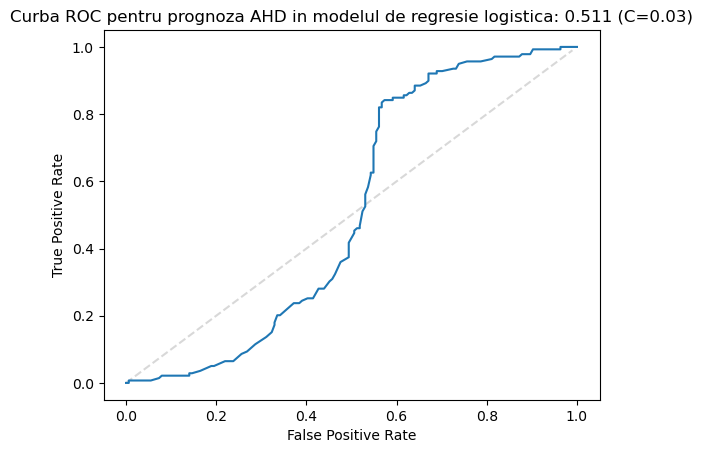

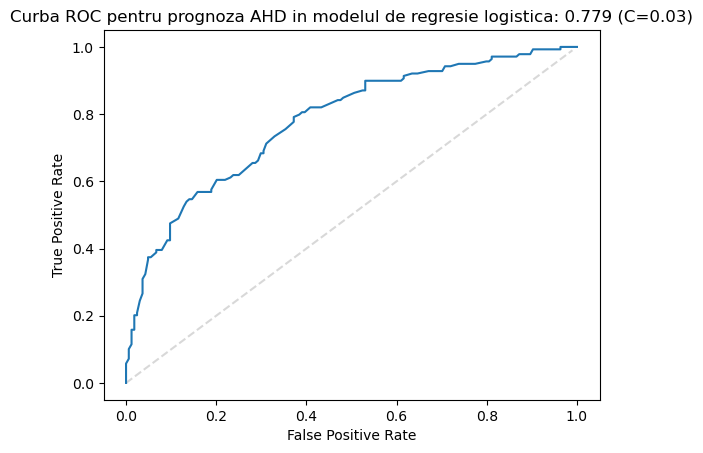

In [50]:
from sklearn.metrics import roc_auc_score
C = 0.03
logitm_l1 = LogisticRegression(C = C, penalty = "l1", solver='liblinear',max_iter=2000)
logitm_l1.fit (data_x, data_y)
logitm_l2 = LogisticRegression(C = C, penalty = "l2", solver='lbfgs')
logitm_l2.fit (data_x, data_y)

def print_auc(C, model, data_x, data_y):
    fpr, tpr, thresholds = met.roc_curve(data_y, model.predict_proba(data_x)[:,1])

    x=np.arange(0,100)/100
    plt.plot(x,x,'--',color="gray",alpha=0.3)
    plt.plot(fpr,tpr)
    plt.ylabel("True Positive Rate")
    plt.xlabel("False Positive Rate")
    plt.title(f"Curba ROC pentru prognoza AHD in modelul de regresie logistica: {roc_auc_score(data_y, model.predict_proba(data_x)[:,1]):0.3f} (C={C})")
    plt.show()   

print_auc(0.03, logitm_l1, data_x, data_y)
print_auc(0.03, logitm_l2, data_x, data_y)

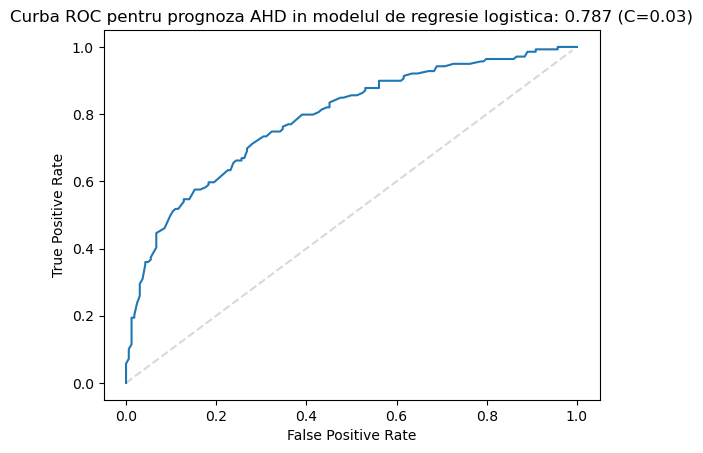

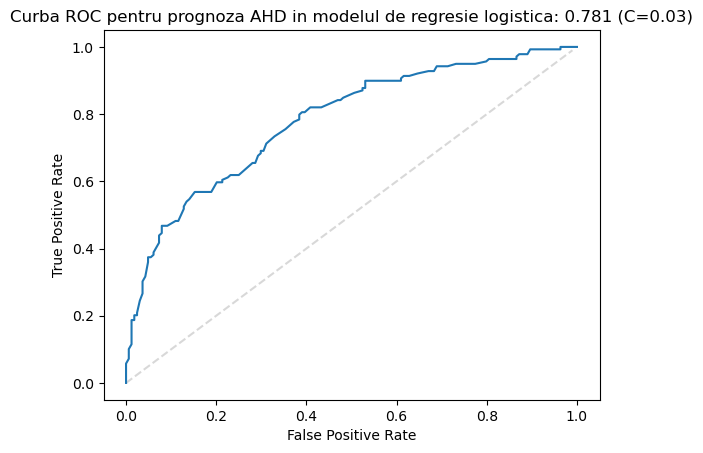

In [51]:
C = 0.8
logitm_l1 = LogisticRegression(C = C, penalty = "l1", solver='liblinear',max_iter=2000)
logitm_l1.fit (data_x, data_y)
logitm_l2 = LogisticRegression(C = C, penalty = "l2", solver='lbfgs')
logitm_l2.fit (data_x, data_y)

def print_auc(C, model, data_x, data_y):
    fpr, tpr, thresholds = met.roc_curve(data_y, model.predict_proba(data_x)[:,1])

    x=np.arange(0,100)/100
    plt.plot(x,x,'--',color="gray",alpha=0.3)
    plt.plot(fpr,tpr)
    plt.ylabel("True Positive Rate")
    plt.xlabel("False Positive Rate")
    plt.title(f"Curba ROC pentru prognoza AHD in modelul de regresie logistica: {roc_auc_score(data_y, model.predict_proba(data_x)[:,1]):0.3f} (C={C})")
    plt.show()   

print_auc(0.03, logitm_l1, data_x, data_y)
print_auc(0.03, logitm_l2, data_x, data_y)

## Puntea curs → seminar

**Concepte cheie**

1. **Probabilitate și prag de decizie:** regresia logistică dă o probabilitate; pragul o transformă în clasă.
2. **Frontiera de decizie:** liniară (logistică, SVM liniar) sau flexibilă (arbori, kNN, SVM cu kernel).
3. **Arbori și ansambluri:** un arbore e ușor de explicat; random forest și boosting sunt mai precise.
4. **Matricea de confuzie:** fals pozitivi și fals negativi au costuri diferite.

**Ce ceri asistentului AI** (exemplu de cerere)

> Pe `lab-set1`, prezice `Churn` cu regresie logistică și cu random forest. Pune deoparte 20% date de test stratificat, codifică variabilele categoriale într-un pipeline, apoi afișează matricea de confuzie și raportul de clasificare pentru fiecare model. Explică ce înseamnă un fals negativ pentru firmă.

**Ce verifici înainte să accepți rezultatul**

- [ ] împărțirea train/test este stratificată, iar codificarea este învățată doar pe antrenare;
- [ ] uită-te la recall și precision pe clasa minoritară, nu doar la acuratețe;
- [ ] poți explica de ce un model e mai bun decât celălalt pentru *această* problemă.

Continuăm la seminar: [seminar-05-clasificare.ipynb](seminar-05-clasificare.ipynb).